In [1]:
# Importing library & removing the unnecessary warnings.
import numpy as np
import pandas as pd
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

In [2]:
 # Importing datasets.
hosp_d = pd.read_csv('Hospitalisation details.csv')
med_e = pd.read_csv('Medical Examinations.csv')
name = pd.read_excel('Names.xlsx')

In [3]:
hosp_d.head()

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID
0,Id2335,1992,Jul,9,0,563.84,tier - 2,tier - 3,R1013
1,Id2334,1992,Nov,30,0,570.62,tier - 2,tier - 1,R1013
2,Id2333,1993,Jun,30,0,600.00,tier - 2,tier - 1,R1013
3,Id2332,1992,Sep,13,0,604.54,tier - 3,tier - 3,R1013
4,Id2331,1998,Jul,27,0,637.26,tier - 3,tier - 3,R1013


In [4]:
med_e.head()

,Customer ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker
0,Id1,47.410,7.47,No,No,No,No major surgery,yes
1,Id2,30.360,5.77,No,No,No,No major surgery,yes
2,Id3,34.485,11.87,yes,No,No,2,yes
3,Id4,38.095,6.05,No,No,No,No major surgery,yes
4,Id5,35.530,5.45,No,No,No,No major surgery,yes


In [5]:
name.head()

,Customer ID,name
0,Id1,"Hawks, Ms. Kelly"
1,Id2,"Lehner, Mr. Matthew D"
2,Id3,"Lu, Mr. Phil"
3,Id4,"Osborne, Ms. Kelsey"
4,Id5,"Kadala, Ms. Kristyn"


**1.1 Project Task: Week 1**

**1. Collate the files so that all the information is in one place**

In [9]:
#Merging the hospital and medical file based on the common field -  Customer ID
df = pd.merge(hosp_d, med_e, on = 'Customer ID')

In [10]:
 # Now combine the last dataset Names with previous combined dataset.
ht = pd.merge(df,name,on = 'Customer ID')
ht

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name
0,Id2335,1992,Jul,9,0,563.84,tier - 2,tier - 3,R1013,17.580,4.51,No,No,No,1,No,"German, Mr. Aaron K"
1,Id2334,1992,Nov,30,0,570.62,tier - 2,tier - 1,R1013,17.600,4.39,No,No,No,1,No,"Rosendahl, Mr. Evan P"
2,Id2333,1993,Jun,30,0,600.00,tier - 2,tier - 1,R1013,16.470,6.35,No,No,Yes,1,No,"Albano, Ms. Julie"
3,Id2332,1992,Sep,13,0,604.54,tier - 3,tier - 3,R1013,17.700,6.28,No,No,No,1,No,"Riveros Gonzalez, Mr. Juan D. Sr."
4,Id2331,1998,Jul,27,0,637.26,tier - 3,tier - 3,R1013,22.340,5.57,No,No,No,1,No,"Brietzke, Mr. Jordan"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2330,Id5,1989,Jun,19,0,55135.40,tier - 1,tier - 2,R1012,35.530,5.45,No,No,No,No major surgery,yes,"Kadala, Ms. Kristyn"
2331,Id4,1991,Jun,6,1,58571.07,tier - 1,tier - 3,R1024,38.095,6.05,No,No,No,No major surgery,yes,"Osborne, Ms. Kelsey"
2332,Id3,1970,?,11,3,60021.40,tier - 1,tier - 1,R1012,34.485,11.87,yes,No,No,2,yes,"Lu, Mr. Phil"
2333,Id2,1977,Jun,8,0,62592.87,tier - 2,tier - 3,R1013,30.360,5.77,No,No,No,No major surgery,yes,"Lehner, Mr. Matthew D"


**2. Check for missing values in the dataset**

In [11]:
ht.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2335 entries, 0 to 2334
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             2335 non-null   object 
 1   year                    2335 non-null   object 
 2   month                   2335 non-null   object 
 3   date                    2335 non-null   int64  
 4   children                2335 non-null   int64  
 5   charges                 2335 non-null   float64
 6   Hospital tier           2335 non-null   object 
 7   City tier               2335 non-null   object 
 8   State ID                2335 non-null   object 
 9   BMI                     2335 non-null   float64
 10  HBA1C                   2335 non-null   float64
 11  Heart Issues            2335 non-null   object 
 12  Any Transplants         2335 non-null   object 
 13  Cancer history          2335 non-null   object 
 14  NumberOfMajorSurgeries  2335 non-null   

**3. Find the percentage of rows that have trivial value (for example, ?), and
delete such rows if they do not contain significant information**

In [18]:
#To fetch all the rows that has any 1 column as '?'
trivial_value = ht[ht.eq("?").any(axis=1)]
trivial_value

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name
11,Id2324,1999,Dec,26,0,700.00,?,tier - 3,R1013,22.240,5.04,No,No,No,No major surgery,No,"Duffy, Ms. Meghan K"
13,Id2322,2002,?,19,0,750.00,tier - 3,tier - 1,R1012,21.380,8.01,No,No,No,No major surgery,No,"Street, Ms. Holly"
17,Id2318,1996,?,18,0,770.38,tier - 3,?,R1012,18.820,5.51,yes,No,No,No major surgery,No,"Gagnon, Ms. Candice M"
542,Id1793,1995,Dec,1,3,4827.90,tier - 1,tier - 2,?,18.905,4.91,yes,No,No,1,No,"Capriolo, Mr. Michael"
1046,Id1289,?,Jul,24,0,8534.67,tier - 2,tier - 3,R1024,24.320,11.56,yes,No,No,1,No,"Levine, Ms. Annie J."
1049,Id1286,?,Dec,12,1,8547.69,tier - 2,tier - 1,R1013,29.370,8.01,yes,No,No,1,No,"Ainsley, Ms. Katie M."
1700,Id635,2004,Jul,17,0,15518.18,tier - 2,tier - 3,R1015,25.175,4.96,No,yes,No,1,?,"Bruns, Mr. Zachary T"
1775,Id560,1994,Jul,1,3,17663.14,tier - 1,tier - 3,R1013,23.980,4.90,No,No,No,No major surgery,?,"Pearlman, Mr. Oz"
2165,Id170,2000,Sep,5,1,37165.16,tier - 1,tier - 3,?,37.620,6.32,yes,yes,No,2,yes,"Torphy, Mr. Bobby"
2332,Id3,1970,?,11,3,60021.40,tier - 1,tier - 1,R1012,34.485,11.87,yes,No,No,2,yes,"Lu, Mr. Phil"


In [20]:
trivial_value.shape

(10, 17)

In [23]:
 # Percentage of row that have the trivial values
round(trivial_value.shape[0]/ht.shape[0]*100,2)

0.43

Observation : There is total 0.43% of rows contain the trivial values.

In [25]:
# Now lets drop the all row that contain the trivial values in the data set.
ht.drop(ht[ht.eq("?").any(axis=1)].index, axis=0, inplace=True)

In [26]:
ht.shape

(2325, 17)

Now all the 10 rows that had the trivial values got removed from the dataframe

**4.Use the necessary transformation methods to deal with the nominal and ordinal
categorical variables in the dataset.**

In [27]:
ht_categorical = ht.select_dtypes(exclude='number')
ht_categorical.head()

,Customer ID,year,month,Hospital tier,City tier,State ID,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name
0,Id2335,1992,Jul,tier - 2,tier - 3,R1013,No,No,No,1,No,"German, Mr. Aaron K"
1,Id2334,1992,Nov,tier - 2,tier - 1,R1013,No,No,No,1,No,"Rosendahl, Mr. Evan P"
2,Id2333,1993,Jun,tier - 2,tier - 1,R1013,No,No,Yes,1,No,"Albano, Ms. Julie"
3,Id2332,1992,Sep,tier - 3,tier - 3,R1013,No,No,No,1,No,"Riveros Gonzalez, Mr. Juan D. Sr."
4,Id2331,1998,Jul,tier - 3,tier - 3,R1013,No,No,No,1,No,"Brietzke, Mr. Jordan"


In [28]:
ht["Heart Issues"].value_counts()

,count
Heart Issues,
No,1405
yes,920


In [29]:
ht["Any Transplants"].value_counts()

,count
Any Transplants,
No,2183
yes,142


In [30]:
ht["Cancer history"].value_counts()

,count
Cancer history,
No,1934
Yes,391


In [31]:
ht["smoker"].value_counts()

,count
smoker,
No,1839
yes,486


In [32]:
 # We have some categorical values so first of all we have to transform then by using the label encoder.
from sklearn.preprocessing import LabelEncoder

In [33]:
le = LabelEncoder()

In [34]:
ht["Heart Issues"] = le.fit_transform(ht["Heart Issues"])
ht["Any Transplants"] = le.fit_transform(ht["Any Transplants"])
ht["Cancer history"] = le.fit_transform(ht["Cancer history"])
ht["smoker"] = le.fit_transform(ht["smoker"])

In [35]:
ht["Heart Issues"].value_counts()

,count
Heart Issues,
0,1405
1,920


In [36]:
ht["Any Transplants"].value_counts()

,count
Any Transplants,
0,2183
1,142


In [37]:
ht.head()

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name
0,Id2335,1992,Jul,9,0,563.84,tier - 2,tier - 3,R1013,17.58,4.51,0,0,0,1,0,"German, Mr. Aaron K"
1,Id2334,1992,Nov,30,0,570.62,tier - 2,tier - 1,R1013,17.60,4.39,0,0,0,1,0,"Rosendahl, Mr. Evan P"
2,Id2333,1993,Jun,30,0,600.00,tier - 2,tier - 1,R1013,16.47,6.35,0,0,1,1,0,"Albano, Ms. Julie"
3,Id2332,1992,Sep,13,0,604.54,tier - 3,tier - 3,R1013,17.70,6.28,0,0,0,1,0,"Riveros Gonzalez, Mr. Juan D. Sr."
4,Id2331,1998,Jul,27,0,637.26,tier - 3,tier - 3,R1013,22.34,5.57,0,0,0,1,0,"Brietzke, Mr. Jordan"


Now we could see that all the "Yes" and "No" are changed to 1s and 0s using label encoding

Now we will deal with the ordinal categorical variable.

In [39]:
def clean_ordinal_variable(val):
  return int(val.replace("tier", "").replace(" ", "").replace("-", ""))

In [40]:
ht["Hospital tier"] = ht["Hospital tier"].map(clean_ordinal_variable)
ht["City tier"] = ht["City tier"].map(clean_ordinal_variable)

In [41]:
ht["City tier"].value_counts()

,count
City tier,
2,807
3,789
1,729


Now the term "Tier" is removed from the columns "Hospital tier" and "city tier". The data now looks completely ordinal without any prefixes

In [42]:
ht.head()

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name
0,Id2335,1992,Jul,9,0,563.84,2,3,R1013,17.58,4.51,0,0,0,1,0,"German, Mr. Aaron K"
1,Id2334,1992,Nov,30,0,570.62,2,1,R1013,17.60,4.39,0,0,0,1,0,"Rosendahl, Mr. Evan P"
2,Id2333,1993,Jun,30,0,600.00,2,1,R1013,16.47,6.35,0,0,1,1,0,"Albano, Ms. Julie"
3,Id2332,1992,Sep,13,0,604.54,3,3,R1013,17.70,6.28,0,0,0,1,0,"Riveros Gonzalez, Mr. Juan D. Sr."
4,Id2331,1998,Jul,27,0,637.26,3,3,R1013,22.34,5.57,0,0,0,1,0,"Brietzke, Mr. Jordan"


**5.The dataset has State ID, which has around 16 states. All states are not
represented in equal proportions in the data. Creating dummy variables for all
regions may also result in too many insignificant predictors. Nevertheless,
only R1011, R1012, and R1013 are worth investigating further. Create a suitable
strategy to create dummy variables with these restraints.**

In [43]:
ht["State ID"].value_counts()

,count
State ID,
R1013,609
R1011,574
R1012,572
R1024,159
R1026,84
R1021,70
R1016,64
R1025,40
R1023,38


It is clear from the above code some of the state is worth investigator like R1013, R1012, R1011 and R1024.

In [74]:
#Moving only those 3 state enteries into separate dataframe
data = ht[ht['State ID'].isin(['R1011', 'R1012', 'R1013'])]
data.shape

(1755, 17)

In [75]:
#Encoding the State IDs to numerical values using Label Encoding
data['State ID'] = le.fit_transform(data['State ID'])

In [76]:
data['State ID'].unique()

array([2, 1, 0])

**6.The variable NumberOfMajorSurgeries also appears to have string values. Apply a
suitable method to clean up this variable.**


In [77]:
data['NumberOfMajorSurgeries'].value_counts()

,count
NumberOfMajorSurgeries,
No major surgery,816
1,713
2,208
3,18


The Number Of Major Surgeries variable contain string value no major Surgery that means 0
surgery so we will replace this value into int value equal to zero

In [78]:
data['NumberOfMajorSurgeries']=data['NumberOfMajorSurgeries'].replace("No major surgery",0)

In [79]:
data['NumberOfMajorSurgeries'].value_counts()

,count
NumberOfMajorSurgeries,
0,816
1,713
2,208
3,18


In [80]:
data.head()

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name
0,Id2335,1992,Jul,9,0,563.84,2,3,2,17.58,4.51,0,0,0,1,0,"German, Mr. Aaron K"
1,Id2334,1992,Nov,30,0,570.62,2,1,2,17.60,4.39,0,0,0,1,0,"Rosendahl, Mr. Evan P"
2,Id2333,1993,Jun,30,0,600.00,2,1,2,16.47,6.35,0,0,1,1,0,"Albano, Ms. Julie"
3,Id2332,1992,Sep,13,0,604.54,3,3,2,17.70,6.28,0,0,0,1,0,"Riveros Gonzalez, Mr. Juan D. Sr."
4,Id2331,1998,Jul,27,0,637.26,3,3,2,22.34,5.57,0,0,0,1,0,"Brietzke, Mr. Jordan"


**7.Age appears to be a significant factor in this analysis. Calculate the
patients' ages based on their dates of birth.**

In [81]:
from datetime import datetime

In [82]:
# Create a new column 'dob' by concatenating year, month and date columns
data['dob'] = data['year'].astype(str) + ' ' + data['month'] + ' ' + data['date'].astype(str)
# convert the dob column to datetime type using pd.to_datetime()
data['dob'] = pd.to_datetime(data['dob'], format='%Y %b %d')
# calculate the age by subtracting the dob from the current date
data['age'] = (datetime.now() - data['dob']).apply(lambda x: x.days/365.25).astype(int)
# now dropping year , date , months column
data.drop(columns=['year','month','date'],axis=1,inplace=True)

In [83]:
data

,Customer ID,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name,dob,age
0,Id2335,0,563.84,2,3,2,17.58,4.51,0,0,0,1,0,"German, Mr. Aaron K",1992-07-09,34
1,Id2334,0,570.62,2,1,2,17.60,4.39,0,0,0,1,0,"Rosendahl, Mr. Evan P",1992-11-30,33
2,Id2333,0,600.00,2,1,2,16.47,6.35,0,0,1,1,0,"Albano, Ms. Julie",1993-06-30,33
3,Id2332,0,604.54,3,3,2,17.70,6.28,0,0,0,1,0,"Riveros Gonzalez, Mr. Juan D. Sr.",1992-09-13,33
4,Id2331,0,637.26,3,3,2,22.34,5.57,0,0,0,1,0,"Brietzke, Mr. Jordan",1998-07-27,28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2328,Id7,1,51194.56,1,3,0,36.40,6.07,0,0,0,0,1,"Macpherson, Mr. Scott",1994-10-27,31
2329,Id6,0,52590.83,1,3,0,32.80,6.59,0,0,0,0,1,"Baker, Mr. Russell B.",1962-08-04,64
2330,Id5,0,55135.40,1,2,1,35.53,5.45,0,0,0,0,1,"Kadala, Ms. Kristyn",1989-06-19,37
2333,Id2,0,62592.87,2,3,2,30.36,5.77,0,0,0,0,1,"Lehner, Mr. Matthew D",1977-06-08,49


**8.The gender of the patient may be an important factor in determining the cost of
hospitalization. The salutations in a beneficiary's name can be used to determine
their gender. Make a new field for the beneficiary's gender**

the salutation (Ms.) denote the female and (Mr.) denote the male. The gender will play the
inportant role to predict the hospitalization cost so for model building we directly denote the gender
by int.
Male = 0 & Female = 1

In [84]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1755 entries, 0 to 2334
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Customer ID             1755 non-null   object        
 1   children                1755 non-null   int64         
 2   charges                 1755 non-null   float64       
 3   Hospital tier           1755 non-null   int64         
 4   City tier               1755 non-null   int64         
 5   State ID                1755 non-null   int64         
 6   BMI                     1755 non-null   float64       
 7   HBA1C                   1755 non-null   float64       
 8   Heart Issues            1755 non-null   int64         
 9   Any Transplants         1755 non-null   int64         
 10  Cancer history          1755 non-null   int64         
 11  NumberOfMajorSurgeries  1755 non-null   object        
 12  smoker                  1755 non-null   int64        

In [85]:
gender = ['0' if 'Mr.' in name else '1' for name in data['name']]
data['Gender'] = gender
data.head()

,Customer ID,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name,dob,age,Gender
0,Id2335,0,563.84,2,3,2,17.58,4.51,0,0,0,1,0,"German, Mr. Aaron K",1992-07-09,34,0
1,Id2334,0,570.62,2,1,2,17.60,4.39,0,0,0,1,0,"Rosendahl, Mr. Evan P",1992-11-30,33,0
2,Id2333,0,600.00,2,1,2,16.47,6.35,0,0,1,1,0,"Albano, Ms. Julie",1993-06-30,33,1
3,Id2332,0,604.54,3,3,2,17.70,6.28,0,0,0,1,0,"Riveros Gonzalez, Mr. Juan D. Sr.",1992-09-13,33,0
4,Id2331,0,637.26,3,3,2,22.34,5.57,0,0,0,1,0,"Brietzke, Mr. Jordan",1998-07-27,28,0


**9.You should also visualize the distribution of costs using a histogram, box and
whisker plot,and swarm plot.**

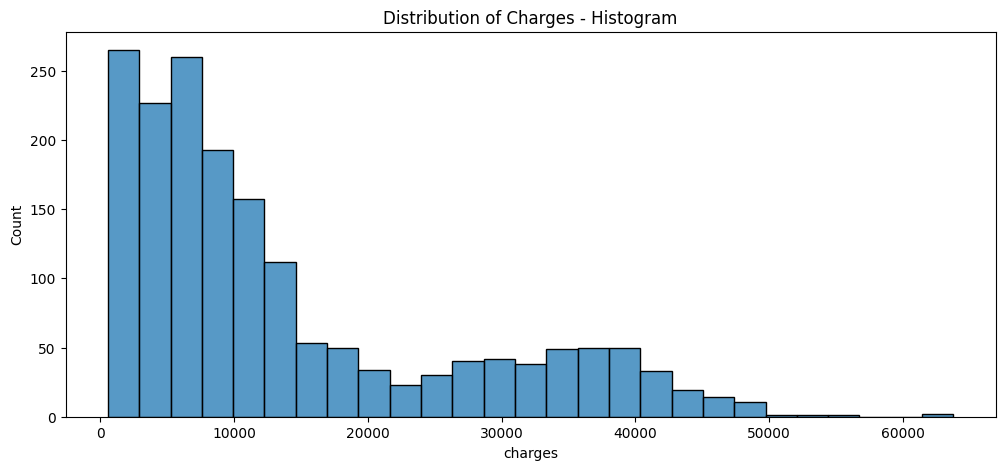

In [89]:
plt.figure(figsize=(12,5))
sns.histplot(data["charges"])
plt.title("Distribution of Charges - Histogram")
plt.show()

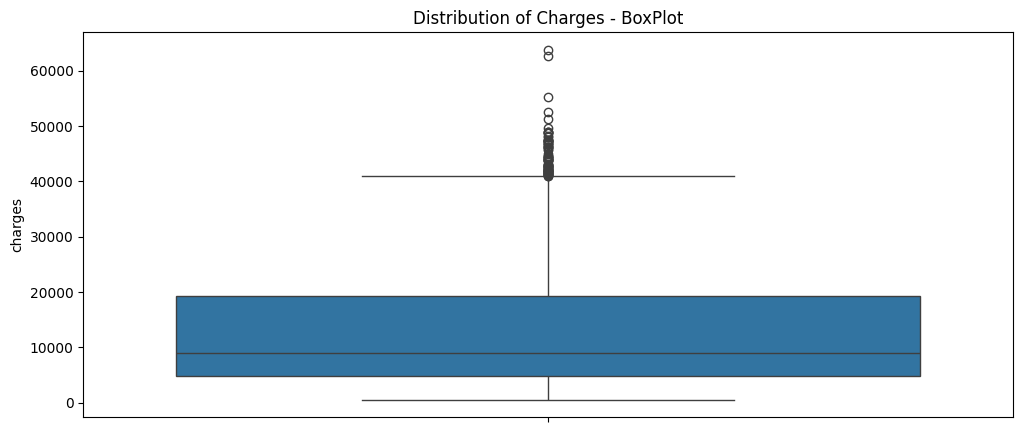

In [91]:
plt.figure(figsize=(12,5))
sns.boxplot(data["charges"])
plt.title("Distribution of Charges - BoxPlot")
plt.show()

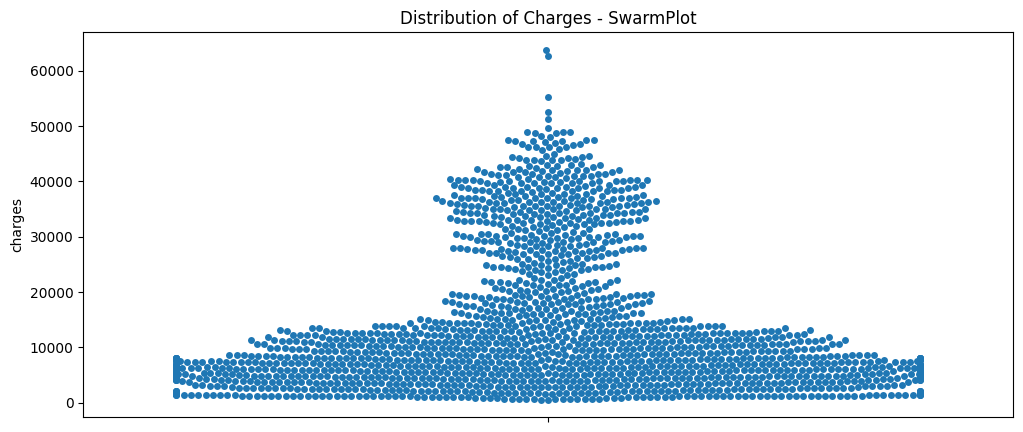

In [93]:
plt.figure(figsize=(12,5))
sns.swarmplot(data["charges"])
plt.title("Distribution of Charges - SwarmPlot")
plt.show()

**10.State how the distribution is different across gender and tiers of hospitals.**

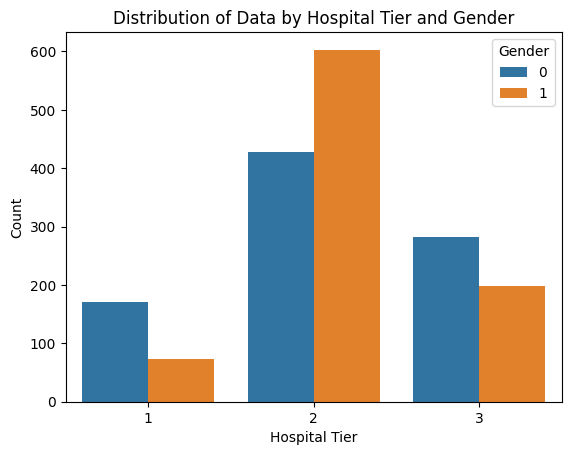

In [94]:
# Create a stacked bar chart
sns.countplot(x='Hospital tier',hue='Gender',data=data)
# Add labels and title
plt.xlabel('Hospital Tier')
plt.ylabel('Count')
plt.title('Distribution of Data by Hospital Tier and Gender')
# Show the plot
plt.show()

**11.Create a radar chart to showcase the median hospitalization cost for each tier
of hospitals.**

In [95]:
import plotly.express as px

In [99]:
aggregated_data = data.groupby('Hospital tier', as_index=False)['charges'].mean()
fig = px.line_polar(aggregated_data, r='charges', theta='Hospital tier', line_close=True)
fig.update_traces(fill='toself')
fig.show()

**12.Create a frequency table and a stacked bar chart to visualize the count of
people in the different tiers of cities and hospitals**

<Axes: xlabel='City tier', ylabel='Count'>

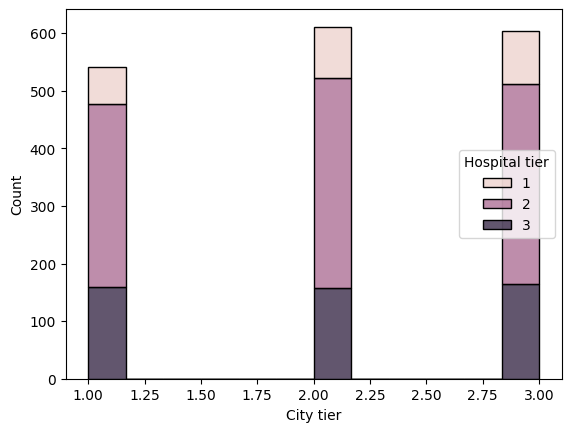

In [100]:
sns.histplot(data,x='City tier' ,hue ='Hospital tier',multiple='stack')

In [101]:
data1 = data

**13.Test the following null hypotheses:**

a.The average hospitalization costs for
the three types of hospitals are not significantly different

---



In [108]:
import scipy.stats as stats
print('Null Hypothesis => Average hospitalization costs for the three types of hospitals are not significantly different.')
# Perform ANOVA test using the `charges` column and grouping by the `Hospital␣tier` column
f_val, p_val = stats.f_oneway(data[data['Hospital tier'] == 'tier -␣1']['charges'],data[data['Hospital tier'] == 'tier -␣2']['charges'],
data[data['Hospital tier'] == 'tier -␣3']['charges'])
# Print the p-value
print('P-value :',p_val)
# Compare p-value with significance value(0.05)
if p_val < 0.05:
  print("Reject null hypothesis")
else:
  print("Accept null hypothesis")


Null Hypothesis => Average hospitalization costs for the three types of hospitals are not significantly different.
P-value : nan
Accept null hypothesis


b.The average hospitalization costs for the three types of cities are not
significantly different.


In [109]:
import scipy.stats as stats
print('Null Hypothesis => Average hospitalization costs for the three types of␣cities are not significantly different.')
# Perform ANOVA test using the `charges` column and grouping by the `City tier`bcolumn
f_val, p_val = stats.f_oneway(data[data['City tier'] == 'tier - 1']['charges'],
data[data['City tier'] == 'tier - 2']['charges'],
data[data['City tier'] == 'tier - 3']['charges'])
# Print the p-value
print('P-value :',p_val)
# Compare p-value with significance value(0.05)
if p_val < 0.05:
  print("Reject null hypothesis")
else:
  print("Accept null hypothesis")

Null Hypothesis => Average hospitalization costs for the three types of␣cities are not significantly different.
P-value : nan
Accept null hypothesis


c.The average hospitalization cost for smokers is not significantly different
from the average cost for nonsmokers.

In [110]:
import scipy.stats as stats
print('Null Hypothesis => Average hospitalization costs for  smokers is not significantly different from the average cost for nonsmokers.')
# Perform ANOVA test using the `charges` column and grouping by the `City tier`bcolumn
t_val, p_val = stats.ttest_ind(data[data['smoker'] == 'yes']['charges'],
data[data['smoker'] == 'No']['charges'])
# Print the p-value
print('P-value :',p_val)
# Compare p-value with significance value(0.05)
if p_val < 0.05:
  print("Reject null hypothesis")
else:
  print("Accept null hypothesis")

Null Hypothesis => Average hospitalization costs for  smokers is not significantly different from the average cost for nonsmokers.
P-value : nan
Accept null hypothesis


d.Smoking and heart issues are independent

In [112]:
import pandas as pd
from scipy.stats import chi2_contingency
# create a contingency table of the observed counts
contingency_table = pd.crosstab(data['smoker'], data['Heart Issues'])
# conduct the chi-squared test
chi2, p, dof, expected = chi2_contingency(contingency_table)
print(f'P-value = {p}')
# interpret the p-value
if p < 0.05:
  print("Reject the null hypothesis, Smoking and heart issues are independent.")
else:
  print("Accept null hypothesis, Smoking and heart issues are independent.")

P-value = 0.9107065371179246
Accept null hypothesis, Smoking and heart issues are independent.


**2 Project Task: Week 2**

**2.0.1 Machine Learning**

**1.Examine the correlation between predictors to identify highly correlated
predictors. Use a heatmap to visualize this.**

In [113]:
# In the data frame same of the column are not usable to model building so lets␣first drop all.
# then indentify the highly corelated predictor.
data.drop(["Customer ID",'name', 'dob'], inplace=True, axis=1)


<Axes: >

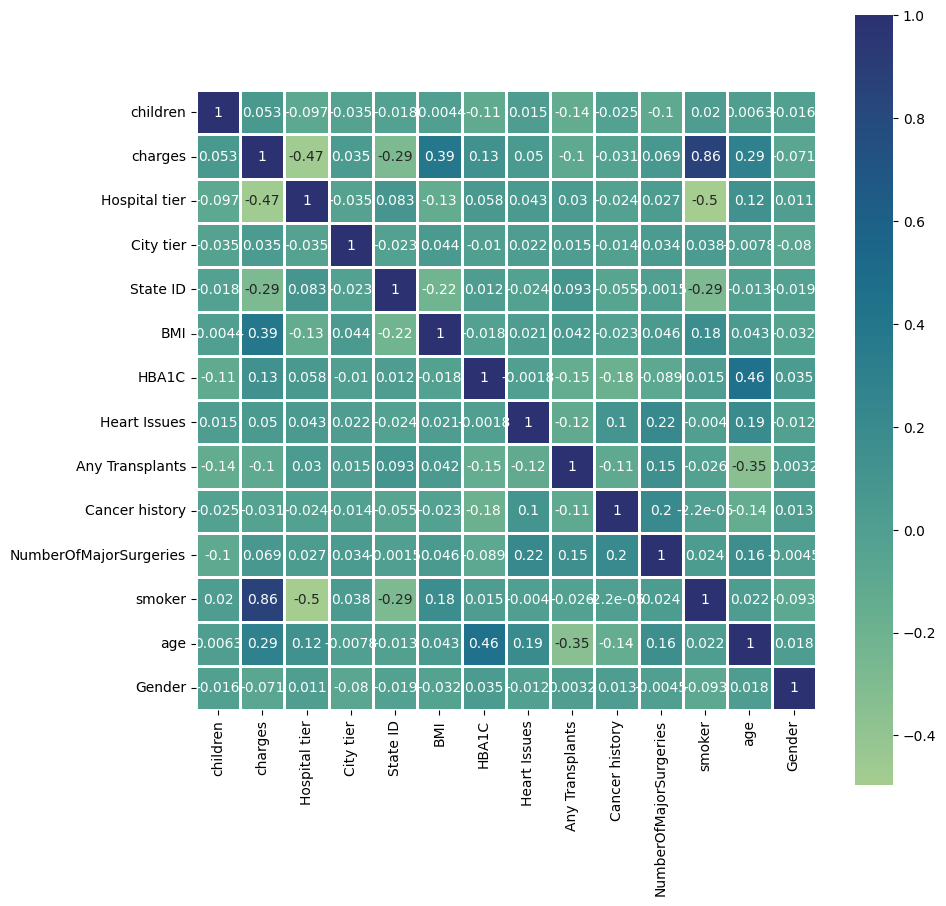

In [114]:
plt.figure(figsize=(10,10))
sns.heatmap(data.corr(),square=True,annot=True,linewidths=1, cmap="crest")

**2.Develop and evaluate the final model using regression with a stochastic
gradient descent optimizer. Also, ensure that you apply all the following
suggestions:**

Note:

•Perform the stratified 5 fold cross validation technique
for model building and validation

•Use standardization and hyperparameter tuning
effectively

•Use-sklearn pipelines

•Use appropriate regularization techniques
to address the bias variance trade off

**a.Create five folds in the data, and
introduce a variable to identify the fold**

**b.For each fold, run a for loop and
ensure that 80 percent of the data is used to train the model and the remaining
20 percent is used to validate it in each iteration**

**c.Develop five distinct
models and five distinct validation scores (root mean squared error values)**

**d.Determine the variable importance scores, and identify the redundant variables**

In [115]:
# lets first seperate the input and output data.
x = data.drop(["charges"], axis=1)
y = data[['charges']]


In [116]:
# Lets split the data set into the training and testing data.
from sklearn.model_selection import train_test_split

In [117]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=.20,random_state=10)

In [121]:
# Now standardize the data.
from sklearn.preprocessing import StandardScaler

In [119]:
sc = StandardScaler()

In [120]:
x_train = sc.fit_transform(x_train)
x_test = sc.fit_transform(x_test)

In [122]:
from sklearn.ensemble import GradientBoostingRegressor

In [123]:
# Instantiate model with 1000 decision trees
gbr = GradientBoostingRegressor(n_estimators = 1000, random_state = 42)
# Train the model on training data
gbr.fit(x_train, y_train)

GradientBoostingRegressor(n_estimators=1000, random_state=42)

In [124]:
score = gbr.score(x_test,y_test)
score

0.8959553467257273

In [125]:
y_pred = gbr.predict(x_test)

In [127]:
from sklearn.metrics import mean_absolute_error
gbr_mae = mean_absolute_error(y_test, y_pred)
gbr_mae

2477.729980343245

**3. Case scenario: Estimate the cost of hospitalization for Christopher, Ms. Jayna
(her date of birth is 12/28/1988, height is 170 cm, and weight is 85 kgs). She
lives in a tier 1 city and her state’s State ID is R1011. She lives with her
partner and two children. She was found to be nondiabetic (HbA1c = 5.8). She
smokes but is otherwise healthy. She has had no transplants or major surgeries.
Her father died of lung cancer. Hospitalization costs will be estimated using
tier 1 hospitals.**

In [162]:
import datetime as dt

In [140]:
# First we need to calculate the age of the person.
date = str(19881228)
date1 = pd.to_datetime(date, format = "%Y%m%d")

In [141]:
current_date = dt.datetime.now()
current_date

datetime.datetime(2026, 9, 11, 18, 10, 44, 145084)

In [154]:
age = current_date - date1
age

Timedelta('13771 days 18:10:44.145084')

In [155]:
age = int(age.days/365)
age

37

In [157]:
# now with the help of height and weight we will calculate the BMI.
height_m = 170/100
height_sq = height_m*height_m
BMI = 85/height_sq
print(np.round(BMI,2))

29.41


In [158]:
# Now lets generate a list for the column values to enter data into the dataframe
list = [[2,1,1,24.41,5.8,0,0,0,0,1,1,34,0]]

In [159]:
df = pd.DataFrame(list, columns = ['children', 'Hospital tier', 'City tier', 'BMI', 'HBA1C','Heart Issues', 'Any Transplants',
'Cancer history','NumberOfMajorSurgeries','smoker', 'State_ID', 'age', 'gender'] )
df

,children,Hospital tier,City tier,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,State_ID,age,gender
0,2,1,1,24.41,5.8,0,0,0,0,1,1,34,0


**5.Find the predicted hospitalization cost using all five models. The predicted
value should be the mean of the five models' predicted values.**

In [203]:
Hospital_cost = []

In [204]:
# Now lets predict the hospitalization cost through SGDRegressor
from sklearn.linear_model import SGDRegressor as sgd
# 1. Instantiate the model
model = sgd()

# 2. Fit the model (replace X_train and y_train with your actual training variables)
# Note: SGDRegressor requires feature scaling (like StandardScaler) to perform well.
model.fit(x_train, y_train)

# 3. Predict using the trained model instance
Cost1 = model.predict(df)
Hospital_cost.append(Cost1)

In [205]:
# Now lets predict the hospitalization cost through Random Forest
from sklearn.ensemble import RandomForestRegressor as rf
# 1. Initialize the model
model = rf(n_estimators=100, random_state=42)
# 2. Fit the model on your training data (Features, Target)
# Replace 'X_train' and 'y_train' with your actual training variables
model.fit(x_train, y_train)
Cost2 = model.predict(df)
Hospital_cost.append(Cost2)


In [206]:
pip install xgboost

In [207]:
# Now lets predict the hospitalization cost through XGBoost
import xgboost as xgb
# 1. Initialize the Extreme Gradient Boosting Regressor
xgb_regressor = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
# 2. Fit the model on your training data (replace X_train and y_train with your variables)
xgb_regressor.fit(x_train, y_train)
# 3. Predict the hospitalization cost
Cost3 = xgb_regressor.predict(df)
Hospital_cost.append(Cost3)

In [208]:
pip install catboost

In [209]:
from catboost import CatBoostRegressor

# 1. Initialize the CatBoost Regressor
cat_regressor = CatBoostRegressor(iterations=100, learning_rate=0.1, depth=5, random_state=42, verbose=0)

# 2. Fit the model on your training data
cat_regressor.fit(x_train, y_train)

# 3. Predict the hospitalization cost
Cost4 = cat_regressor.predict(df)
Hospital_cost.append(Cost4)

In [212]:
from sklearn.ensemble import AdaBoostRegressor

# 1. Initialize the AdaBoost Regressor
adaboost_regressor = AdaBoostRegressor(n_estimators=100, learning_rate=0.1, random_state=42)

# 2. Fit the model on your training data
adaboost_regressor.fit(x_train, y_train)

# 3. Predict the hospitalization cost
Cost5 = adaboost_regressor.predict(df)
Hospital_cost.append(Cost5)

In [213]:
print(Hospital_cost)

[array([155013.66775881]), array([52108.1976]), array([19901.89], dtype=float32), array([43946.25733665]), array([48308.31378378])]


In [214]:
avg_cost = np.mean(Hospital_cost)
print(avg_cost)

63855.665420847436


So in the new case the avg predicted hospitalization cost is 63855.66
